# Assignment 2 - Part 1: HST Calibration Routine
------

## Objective

TODO

## Steps

TODO

In [20]:
# Packages & import
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from astropy.io import fits

# Custom utils functions import
from hst_utils import load_calibration_files, transform_by    # AUTHOR: Dr Andrew Kirwan

### 0. Import files
-----

In [21]:
# Import the .fits files
calib_dir = Path("hst-calibration")
ubai2505m = load_calibration_files(calib_dir / "ubai2505m")

# Logging
print("File type | Data shape |  Data type")
for file_type, (header, data) in ubai2505m.items():
    print(f"{file_type:10s} {str(data.shape):16s} {data.dtype}")


File type | Data shape |  Data type
atodfile   (4, 2, 4096)     >f4
biasfile   (4, 800, 800)    >f4
blevfile   (4, 800, 14)     int16
darkfile   (4, 800, 800)    >f4
flatfile   (4, 800, 800)    >f4
maskfile   (4, 800, 800)    >i2
raw        (4, 800, 800)    >i2


**Visualization of the files**

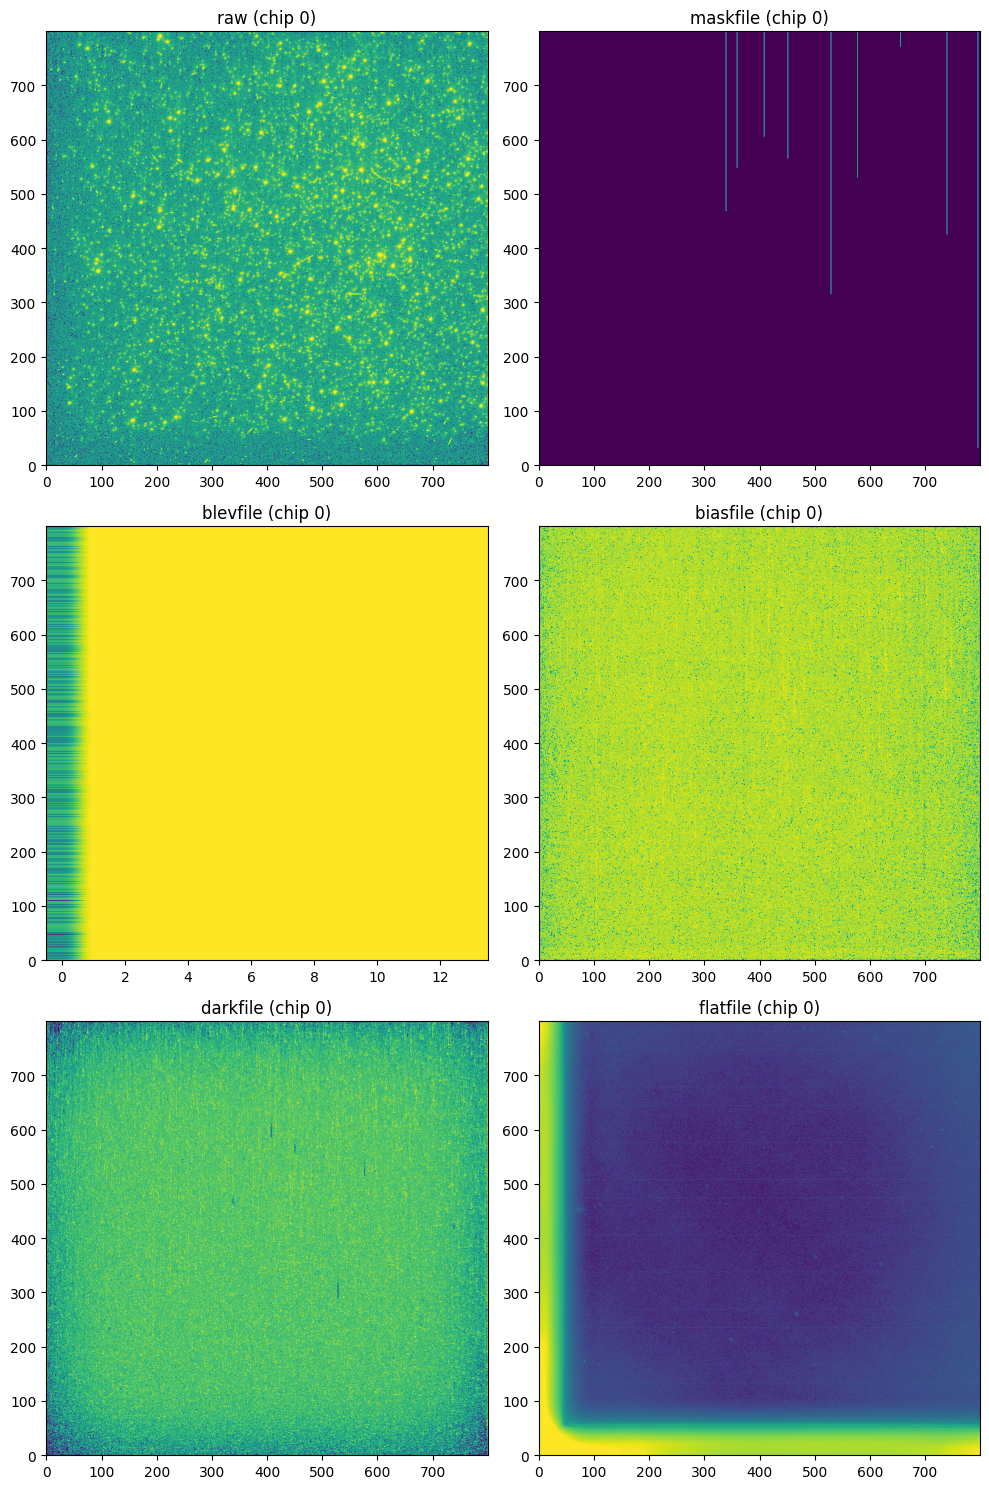

In [22]:
def plot_calibration_files(files, chip=0):
    """
    Plot one chip of the raw and calibration images, two per row.
    """
    names = ['raw', 'maskfile', 'blevfile', 'biasfile', 'darkfile', 'flatfile']
    fig, axes = plt.subplots(3, 2, figsize=(10, 15))
    axes = axes.ravel()

    for i in range(len(names)):
        data = files[names[i]][1][chip]
        # The mask only has the values 0, 2 and 256, so no log stretch
        if names[i] == 'maskfile':
            image = transform_by('linear', data, pmin=0, pmax=100)
        else:
            image = transform_by('log', data, pmin=1, pmax=99)
        axes[i].imshow(image, origin='lower', aspect='auto')
        axes[i].set_title(f"{names[i]} (chip {chip})")

    fig.tight_layout()
    plt.show()


plot_calibration_files(ubai2505m, chip=0)


### 1. Mask invalid data with `MASKFILE`
The mask indicates all bad pixels as follows:
 - 0 represents a valid pixels
 - 2 represents defective pixels
 - 256 represents 'questionable pixels'
-----

In [23]:
mask_header, mask_data = ubai2505m['maskfile']

# Statistics on the number of valid, defective, and questionable pixels
print('Maskfile statistics')
for chip in range(mask_data.shape[0]):
    total = mask_data[chip].size
    valid = np.sum(mask_data[chip] == 0)
    defective = np.sum(mask_data[chip] == 2)
    questionable = np.sum(mask_data[chip] == 256)
    print(f"Chip {chip}: total = {total}, "
          f"valid = {valid} ({100 * valid / total:.2f}%), "
          f"defective = {defective} ({100 * defective / total:.2f}%), "
          f"questionable = {questionable} ({100 * questionable / total:.2f}%)")

Maskfile statistics
Chip 0: total = 640000, valid = 635890 (99.36%), defective = 1169 (0.18%), questionable = 2941 (0.46%)
Chip 1: total = 640000, valid = 635586 (99.31%), defective = 1697 (0.27%), questionable = 2717 (0.42%)
Chip 2: total = 640000, valid = 637684 (99.64%), defective = 1171 (0.18%), questionable = 1145 (0.18%)
Chip 3: total = 640000, valid = 632032 (98.75%), defective = 1393 (0.22%), questionable = 6575 (1.03%)


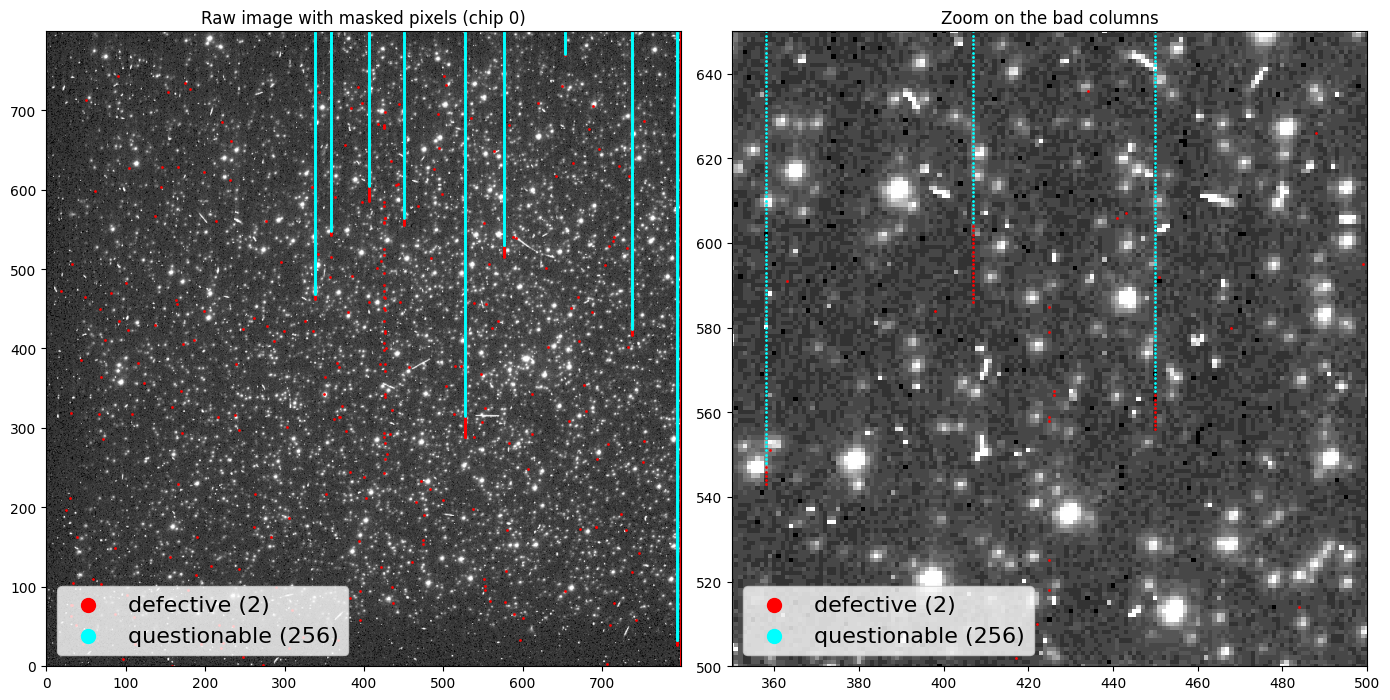

In [ ]:
# Plot the maskfile on top of the rawfile, clearly highlighting the masked pixels.
# A second plot zooms on the area where there are some bad columns.
chip = 0
raw_header, raw_data = ubai2505m['raw']
raw_image = transform_by('sqrt', raw_data[chip], pmin=1, pmax=99)

defective_y, defective_x = np.where(mask_data[chip] == 2)
questionable_y, questionable_x = np.where(mask_data[chip] == 256)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 7))
for ax in [ax1, ax2]:
    ax.imshow(raw_image, origin='lower', cmap='gray')
    ax.scatter(defective_x, defective_y, s=1, color='red', label='defective (2)')
    ax.scatter(questionable_x, questionable_y, s=1, color='cyan', label='questionable (256)', )

ax1.set_title(f'Raw image with masked pixels (chip {chip})')
ax1.legend(loc='lower left', markerscale=10, fontsize=16)

ax2.set_xlim(350, 500)
ax2.set_ylim(500, 650)
ax2.set_title('Zoom on the bad columns')
ax2.legend(loc='lower left', markerscale=10, fontsize=16)


fig.tight_layout()
plt.show()

**We observe:**
1. Some defective individuels pixels on the image
2. Some defective pixels on the same column, on top of each other
3. For those defective pixels on top of each other, all pixels on top of them in these columns are classified as 'questionable'

**Analysis:**

According to \url{https://www.stsci.edu/instrument-news/isr/wfpc2/9503/9503_1.html}, these effects are due to **charge traps**: single pixels that don't pass charge along properly. As CCDs are read columns by columns, all previous pixels in the column are considered as 'questionable'

**Decision:**

As the statistics show that less of 1% of the pixels are defective or questionable, and as recommended on the previous cited source, the chosen decision is to mask the defective and questionable pixels with Nan values. Note that the usage of nan-safe functions is thus required from now on.

Another, more complex approach would have been to interpolate these pixels, but we decided not to do so as it would create fake data into our measurements

In [ ]:
# replace all the defective and questionable pixels by Nan in the raw_data
def mask_invalid_data(raw_data, mask_data):
    """
    Return a float copy of raw_data where the defective (2) and
    questionable (256) pixels of mask_data are set to NaN.
    """
    raw_data_masked = raw_data.astype(float)
    raw_data_masked[(mask_data == 2) | (mask_data == 256)] = np.nan
    return raw_data_masked

raw_data_masked = mask_invalid_data(raw_data, mask_data)
# Check: number of masked pixels per chip
for chip in range(raw_data_masked.shape[0]):
    print(f"Chip {chip}: {np.sum(np.isnan(raw_data_masked[chip]))} pixels set to NaN")


Chip 0: 4110 pixels set to NaN
Chip 1: 4414 pixels set to NaN
Chip 2: 2316 pixels set to NaN
Chip 3: 7968 pixels set to NaN


### 2. Correct Analog-to-Digital conversion errors with `ATODFILE`
-----
**Not required**: the `raw.fits` files given are already ADC-corrected

### 3. Remove bias level with `BLEVFILE`
-----
TODO